In [1]:
#import libraries 
import os 
import pandas as pd 
from datasets import load_dataset 
import matplotlib.pyplot as plt 
import ast
import seaborn as sns

#path for local caching 

file_path="data_jobs.parquet"

#loading data 
if not os.path.exists(file_path):
    dataset=load_dataset('lukebarousse/data_jobs') 
    df=dataset['train'].to_pandas()
    df.to_parquet(file_path)
else:
    df=pd.read_parquet(file_path)

#data cleanup 
df['job_posted_date']=pd.to_datetime(df['job_posted_date'])
df['job_skills']=df['job_skills'].apply(lambda skill_list2: ast.literal_eval(skill_list2) if isinstance(skill_list2,str) else skill_list2 )




In [2]:
df_DA_US=df[(df['job_title_short']=='Data Analyst')&(df['job_country']=='United States')].copy()


In [4]:
df_DA_US=df_DA_US.dropna(subset=['salary_year_avg'])
df_DA_US_exploded=df_DA_US.explode('job_skills')
df_DA_US_exploded[['salary_year_avg','job_skills']].head(5)




,salary_year_avg,job_skills
109,89000.0,python
109,89000.0,r
109,89000.0,alteryx
109,89000.0,tableau
180,90250.0,excel


In [10]:
df_DA_skills=df_DA_US_exploded.groupby('job_skills')['salary_year_avg'].agg(['count','median']).sort_values(by='count',ascending=False)
df_DA_skills=df_DA_skills.rename(columns={'count':'skill_count','median':'median_salary'})
DA_job_count=len(df_DA_US)
df_DA_skills['skill_percent']=df_DA_skills['skill_count']/DA_job_count*100
skill_percent=5 
df_DA_skills_high_demand=df_DA_skills[df_DA_skills['skill_percent']> skill_percent]
df_DA_skills_high_demand

,skill_count,median_salary,skill_percent
job_skills,,,
sql,2508,91000.00,57.655172
excel,1808,84392.00,41.563218
python,1431,97500.00,32.896552
tableau,1364,92875.00,31.356322
sas,926,90000.00,21.287356
r,893,92500.00,20.528736
power bi,838,90000.00,19.264368
powerpoint,462,85000.00,10.620690
word,461,81194.75,10.597701


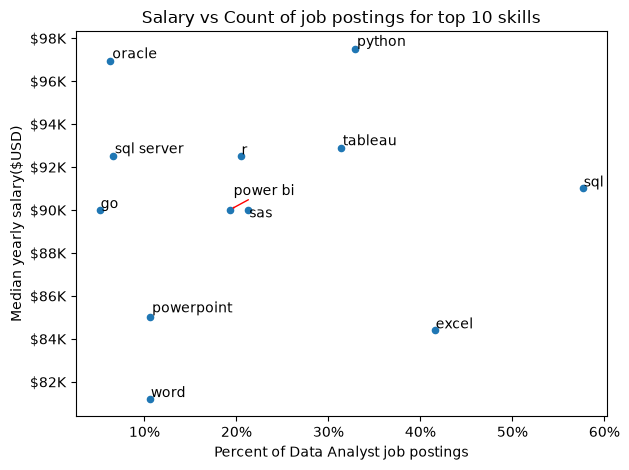

In [20]:
# inserted comma in x axis using chatgpt
from adjustText import adjust_text 

# fig,ax=plt.subplots()

# df_DA_skills_high_demand=df_DA_skills_high_demand.groupby('job_skills').agg(
#     skill_count=('job_skills','count'), 
#     median_salary=('salary_year_avg','median')

# )

# skill_count=20
# df_DA_skills_high_demand=df_DA_skills_high_demand.sort_values(by='skill_count',ascending=False).head(skill_count)

df_DA_skills_high_demand.plot(kind='scatter',x='skill_percent',y='median_salary')
ax=plt.gca()
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y,pos:f'${int(y/1000)}k'))
plt.xlabel('Percent of Data Analyst job postings')
plt.ylabel('Median yearly salary($USD)')
plt.title('Salary vs Count of job postings for top 10 skills')
from matplotlib.ticker import PercentFormatter
ax=plt.gca()
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y,pos:f'${int(y/1000)}K'))
ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
plt.tight_layout()

texts=[]
for i,txt in enumerate(df_DA_skills_high_demand.index):
    texts.append(plt.text(df_DA_skills_high_demand['skill_percent'].iloc[i],df_DA_skills_high_demand['median_salary'].iloc[i],txt))

adjust_text(texts,arrowprops=dict(arrowstyle='->',color='red'))
plt.show()
from adjustText import adjust_text 

# df_DA_skills_high_demand = df_DA_skills_high_demand.groupby('job_skills').agg(
#     skill_count=('job_skills', 'count'), 
#     median_salary=('salary_year_avg', 'median_salary')
# )

# skill_count = 20
# df_DA_skills_high_demand = df_DA_skills_high_demand.sort_values(
#     by='skill_count', 
#     ascending=False
# ).head(skill_count)

# df_DA_skills_high_demand.plot(
#     kind='scatter',
#     x='skill_count',
#     y='median_salary'
# )

# ax = plt.gca()

# # X-axis: add commas
# ax.xaxis.set_major_formatter(
#     plt.FuncFormatter(lambda x, pos: f'{int(x):,}')
# )

# # Y-axis: show salary as $XXk
# ax.yaxis.set_major_formatter(
#     plt.FuncFormatter(lambda y, pos: f'${int(y/1000)}k')
# )

# plt.xlabel('Count of job postings')
# plt.ylabel('Median yearly salary ($USD)')
# plt.title('Salary vs Count of job postings for top 20 skills')
# plt.tight_layout()

# texts = []

# for i, txt in enumerate(df_DA_skills_high_demand.index):
#     texts.append(
#         plt.text(
#             df_DA_skills_high_demand['skill_count'].iloc[i],
#             df_DA_skills_high_demand['median_salary'].iloc[i],
#             txt
#         )
#     )

# adjust_text(
#     texts,
#     arrowprops=dict(arrowstyle='->', color='red')
# )

# plt.show()

In [21]:
df['job_type_skills'].head(10)

0                                                  NaN
1    {'analyst_tools': ['power bi', 'tableau'], 'pr...
2    {'analyst_tools': ['dax'], 'cloud': ['azure'],...
3    {'cloud': ['aws'], 'libraries': ['tensorflow',...
4    {'cloud': ['oracle', 'aws'], 'other': ['ansibl...
5    {'cloud': ['gcp'], 'programming': ['python', '...
6    {'cloud': ['gcp', 'bigquery'], 'databases': ['...
7    {'cloud': ['gcp', 'azure', 'aws', 'bigquery', ...
8    {'analyst_tools': ['excel', 'powerpoint', 'pow...
9    {'analyst_tools': ['excel'], 'cloud': ['azure'...
Name: job_type_skills, dtype: str

In [24]:
df_technology=df['job_type_skills'].copy()

df_technology=df_technology.drop_duplicates()

df_technology=df_technology.dropna()

technology_dict={}

for row in df_technology:
    row_dict=ast.literal_eval(row)
    for key,value in row_dict.items():
        if key in technology_dict:
            technology_dict[key] +=value 
        else:
            technology_dict[key]=value 

for key,value in technology_dict.items():
    technology_dict[key]=list(set(value))

technology_dict

{'analyst_tools': ['power bi',
  'sharepoint',
  'alteryx',
  'splunk',
  'microstrategy',
  'ms access',
  'visio',
  'powerbi',
  'dax',
  'excel',
  'spreadsheet',
  'nuix',
  'msaccess',
  'spss',
  'powerpoint',
  'outlook',
  'qlik',
  'datarobot',
  'esquisse',
  'ssis',
  'looker',
  'tableau',
  'word',
  'ssrs',
  'sap',
  'sheets',
  'sas',
  'cognos'],
 'programming': ['sql',
  'c++',
  'kotlin',
  'golang',
  'assembly',
  'mongodb',
  'cobol',
  'shell',
  'vba',
  'lisp',
  'visualbasic',
  't-sql',
  'crystal',
  'vb.net',
  'sass',
  'c',
  'scala',
  'go',
  'haskell',
  'html',
  'groovy',
  'f#',
  'r',
  'python',
  'lua',
  'clojure',
  'no-sql',
  'java',
  'solidity',
  'ocaml',
  'delphi',
  'c#',
  'bash',
  'css',
  'ruby',
  'mongo',
  'pascal',
  'php',
  'swift',
  'matlab',
  'javascript',
  'erlang',
  'fortran',
  'powershell',
  'nosql',
  'rust',
  'apl',
  'objective-c',
  'typescript',
  'dart',
  'sas',
  'perl',
  'visual basic',
  'julia',
  'eli

In [25]:
df_technology=pd.DataFrame(list(technology_dict.items()),columns=['technology','skills'])

df_technology=df_technology.explode('skills')

df_technology

,technology,skills
0,analyst_tools,power bi
0,analyst_tools,sharepoint
0,analyst_tools,alteryx
0,analyst_tools,splunk
0,analyst_tools,microstrategy
...,...,...
9,sync,mattermost
9,sync,google chat
9,sync,slack
9,sync,webex


In [28]:
df_plot=df_DA_skills_high_demand.merge(df_technology,left_on='job_skills',right_on='skills')
df_plot

,skill_count,median_salary,skill_percent,technology,skills
0,2508,91000.00,57.655172,programming,sql
1,1808,84392.00,41.563218,analyst_tools,excel
2,1431,97500.00,32.896552,programming,python
3,1364,92875.00,31.356322,analyst_tools,tableau
4,926,90000.00,21.287356,analyst_tools,sas
5,926,90000.00,21.287356,programming,sas
6,893,92500.00,20.528736,programming,r
7,838,90000.00,19.264368,analyst_tools,power bi
8,462,85000.00,10.620690,analyst_tools,powerpoint
9,461,81194.75,10.597701,analyst_tools,word


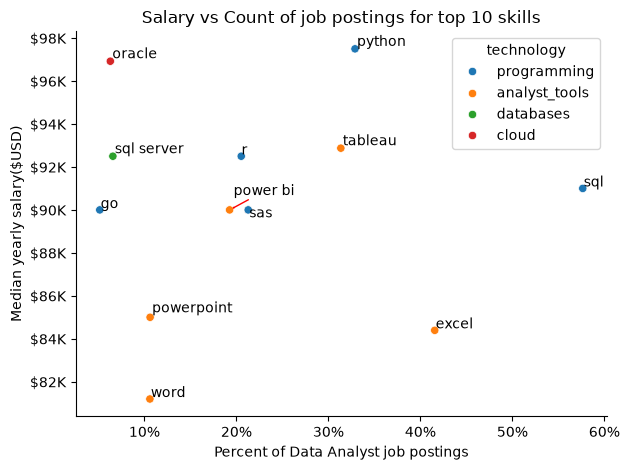

In [30]:
from adjustText import adjust_text 
sns.scatterplot(
    data=df_plot,
    x='skill_percent',
    y='median_salary',
    hue='technology'
)
sns.despine()
ax=plt.gca()
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y,pos:f'${int(y/1000)}k'))
plt.xlabel('Percent of Data Analyst job postings')
plt.ylabel('Median yearly salary($USD)')
plt.title('Salary vs Count of job postings for top 10 skills')
from matplotlib.ticker import PercentFormatter
ax=plt.gca()
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y,pos:f'${int(y/1000)}K'))
ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
plt.tight_layout()

texts=[]
for i,txt in enumerate(df_DA_skills_high_demand.index):
    texts.append(plt.text(df_DA_skills_high_demand['skill_percent'].iloc[i],df_DA_skills_high_demand['median_salary'].iloc[i],txt))

adjust_text(texts,arrowprops=dict(arrowstyle='->',color='red'))
plt.show()